# Dự đoán quan hệ theo thời gian trên PVSG
Tái tạo hình mở đầu, timeline và bảng test bằng CPU từ kết quả M5 đã lưu. Cần PyAV, NumPy, Matplotlib, bộ media và cache hình học PVSG v4 trong workspace. Các khoảng frame đều bao gồm hai đầu mút.

In [1]:
from pathlib import Path
import json
from statistics import mean, stdev
import av
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'report_latex/main.tex').is_file())
results = root/'reports/pvsg-trd-m5-v1'
out = root/'report_latex/figures'
cache = root/'data/external/pvsg_m2_cache_v4'
def read(p):
    return json.loads(p.read_text())
annotation = read(root/read(cache/'dataset.lock.json')['annotation']['local_path'])
objects = {v['video_id']: {o['object_id']: o['category'] for o in v['objects']} for v in annotation['data']}
predicates = annotation['relations']
examples = read(results/'baseline/static_gat/seed-17.json')['details']['case_studies']
def labels(c):
    s,p,o = c['key']
    return objects[c['video']][s], predicates[p], objects[c['video']][o]
def frame_set(segments):
    return {f for a,b in segments for f in range(a,b+1)}
for c in examples:
    gt, pred = frame_set(c['gt']), frame_set(c['pred'])
    assert np.isclose(len(gt & pred)/len(gt | pred), c['tiou'])
    assert (c['tiou'] >= .5) == (c['outcome'] == 'hit')
plt.rcParams.update({'font.family':'serif','font.serif':['Liberation Serif','DejaVu Serif'],
                     'pdf.fonttype':42,'font.size':10})
colors = ['#26745b','#235889']
def timeline(ax, c):
    for y,key,col in zip((1,0),('gt','pred'),colors, strict=False):
        ax.broken_barh([(a-.5,b-a+1) for a,b in c[key]], (y-.28,.56), facecolors=col)
    ax.set(xlim=(-.5,c['frames']-.5),ylim=(-.55,1.55),yticks=[0,1],yticklabels=['Pred','GT'])
    ax.spines[['top','left','right']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6,integer=True))
    ax.grid(axis='x',alpha=.18)

## Ba frame của cùng một cặp có hướng
Đọc frame theo thứ tự giải mã như bước kiểm tra media M2. Bounding box lấy từ mask chuẩn. Mỗi nhãn bên dưới ảnh cho biết frame đó nằm trong tập dự đoán, ground truth hay cả hai.

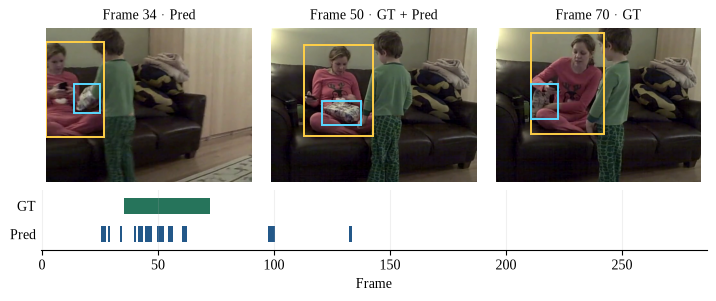

In [2]:
c = next(c for c in examples if c['video']=='0004_11566980553' and c['key']==[8,20,4])
frames = [34,50,70]
vid = c['video']
media = root/'data/external/pvsg_media_v1/videos/vidor'/f'{vid}.mp4'
with av.open(str(media)) as reader:
    images = {i:f.to_ndarray(format='rgb24') for i,f in enumerate(reader.decode(video=0)) if i in frames}
fig = plt.figure(figsize=(7.05,2.9), layout='constrained')
grid = fig.add_gridspec(2,3,height_ratios=[2.6,1])
with np.load(cache/'geometry'/f'{vid}.npz') as geometry:
    for col, f in enumerate(frames):
        ax = fig.add_subplot(grid[0,col])
        ax.imshow(images[f])
        for track, color in zip((c['key'][0],c['key'][2]),('#ffcf47','#59d8ff'), strict=False):
            i = list(geometry['track_ids']).index(track)
            assert geometry['visible'][i,f]
            x,y,u,v = geometry['boxes'][i,f]
            ax.add_patch(Rectangle((x,y),u-x,v-y,fill=False,ec=color,lw=1.4))
        membership = ' + '.join(tag for k,tag in [('gt','GT'),('pred','Pred')] if f in frame_set(c[k]))
        ax.set_title(f'Frame {f} · {membership}',fontsize=10)
        ax.axis('off')
ax = fig.add_subplot(grid[1,:])
timeline(ax,c)
ax.set_xlabel('Frame')
fig.savefig(out/'pvsg-holding.pdf',dpi=220)
plt.show()
plt.close(fig)

## Tần suất 57 predicate trên tập fit
Đếm mỗi bộ ba có hướng một lần trong từng video sau căn chỉnh, kể cả khi có nhiều khoảng thời gian. Thứ tự và cách chia ba nhóm giống bộ chấm M5.

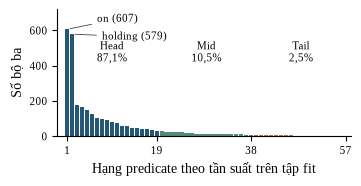

3004 [('on', 607), ('holding', 579)]


In [3]:
from collections import Counter
fit_ids = set(read(cache/'dataset.lock.json')['internal_validation']['fit_ids'])
targets = {v['video_id']: v['relations'] for v in read(cache/'targets.json')}
assert len(fit_ids) == 287 and len(predicates) == 57
counts = Counter()
for vid in sorted(fit_ids):
    triples = [(r['subject_id'],r['predicate_id'],r['object_id']) for r in targets[vid]]
    assert len(triples) == len(set(triples))
    counts.update(predicate for _,predicate,_ in triples)
ranked = sorted(range(len(predicates)), key=lambda p: (-counts[p],p))
bins = read(results/'baseline/static_gat/seed-17.json')['details']['fit_frequency_bins']
fig,ax = plt.subplots(figsize=(3.5,1.75), layout='constrained')
for i,(name,color) in enumerate(zip(('head','mid','tail'),('#245675','#528b7b','#b77936'), strict=False)):
    ids = ranked[19*i:19*i+19]
    assert ids == bins[name]['predicate_ids']
    ax.bar(np.arange(19*i+1,19*i+20), [counts[p] for p in ids], width=.88, color=color)
    share = 100*sum(counts[p] for p in ids)/counts.total()
    ax.text(19*i+10,425, f'{name.title()}\n{share:.1f}%'.replace('.',','), ha='center', fontsize=8)
for rank, y in ((1,665),(2,565)):
    p = ranked[rank-1]
    ax.annotate(f'{predicates[p]} ({counts[p]})', xy=(rank,counts[p]),xytext=(rank+6,y),
                va='center',fontsize=8,arrowprops={'arrowstyle':'-', 'lw':.6,'color':'#464646'})
ax.set(xlim=(-1,58),ylim=(0,720),xticks=[1,19,38,57],yticks=[0,200,400,600],
       xlabel='Hạng predicate theo tần suất trên tập fit',ylabel='Số bộ ba')
ax.tick_params(labelsize=8)
ax.spines[['top','right']].set_visible(False)
fig.savefig(out/'pvsg-fit-predicates.pdf')
plt.show()
plt.close(fig)
print(counts.total(), [(predicates[p],counts[p]) for p in ranked[:2]])

## Cùng một track, hai đoạn quan hệ
Bộ ba ở Hit 2 của bảng timeline. Frame 3 và 67 nằm ở hai đoạn GT khác nhau. Frame 40 nằm giữa hai đoạn và mask chuẩn không có track 5.

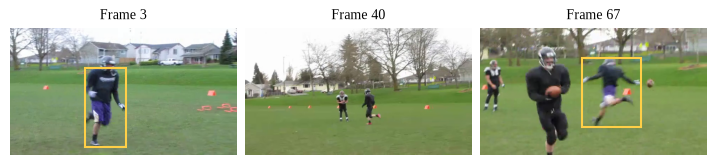

In [4]:
running = next(c for c in examples if c['video']=='0039_6951351121' and c['key']==[5,43,3])
vid = running['video']
subject, predicate, obj = labels(running)
assert (subject,predicate,obj)==('adult','running on','grass') and running['gt']==[[0,10],[65,70]]
selected = (3,40,67)
with av.open(str(root/'data/external/pvsg_media_v1/videos/vidor'/f'{vid}.mp4')) as reader:
    images = {t:f.to_ndarray(format='rgb24') for t,f in enumerate(reader.decode(video=0)) if t in selected}
fig,axes = plt.subplots(1,3,figsize=(7.05,1.55),layout='constrained')
with np.load(cache/'geometry'/f'{vid}.npz') as geometry:
    i = list(geometry['track_ids']).index(running['key'][0])
    for ax,t in zip(axes,selected, strict=False):
        ax.imshow(images[t])
        visible = bool(geometry['visible'][i,t])
        assert visible == (t in (3,67))
        if visible:
            x,y,u,v = geometry['boxes'][i,t]
            ax.add_patch(Rectangle((x,y),u-x,v-y,fill=False,ec='#ffcf47',lw=1.5))
        ax.set_title(f'Frame {t}',fontsize=10)
        ax.axis('off')
fig.savefig(out/'pvsg-running-track.pdf',dpi=220)
plt.show()
plt.close(fig)

## Timeline của năm Hit và năm Miss
Thứ tự ví dụ lấy nguyên từ result của Static GAT, seed 17. Mỗi hàng có trục frame riêng.

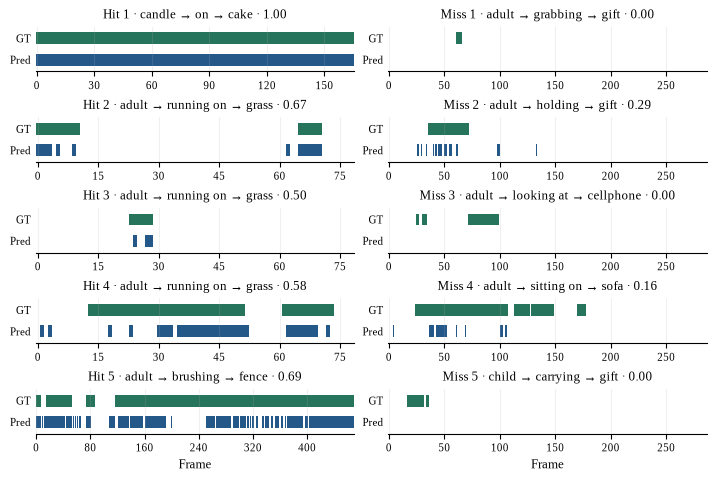

In [5]:
fig,axes = plt.subplots(5,2,figsize=(7.05,4.7),layout='constrained')
for col, outcome in enumerate(('hit','miss')):
    group = [c for c in examples if c['outcome']==outcome]
    assert len(group) == 5
    for row,(ax,c) in enumerate(zip(axes[:,col],group, strict=False)):
        timeline(ax,c)
        s,p,o = labels(c)
        ax.set_title(f'{outcome.title()} {row+1} · {s} → {p} → {o} · {c["tiou"]:.2f}',fontsize=9)
        ax.tick_params(labelsize=8)
        if row==4:
            ax.set_xlabel('Frame',fontsize=9)
fig.savefig(out/'pvsg-case-timelines.pdf')
plt.show()
plt.close(fig)

## Bảng test chính
Chọn lượt huấn luyện theo danh sách đối chiếu đã khóa từ validation. Mỗi cấu hình có ba seed. Giá trị mỗi seed đã ở đơn vị phần trăm.

In [6]:
names = {'mlp':'MLP', 'static_gat':'Static GAT','st_gat':'ST-GAT',
         'st_no_temporal':'ST-GAT bỏ cạnh thời gian','st_no_spatial':'ST-GAT bỏ cạnh không gian',
         'st_no_edges':'ST-GAT chỉ giữ self-loop','mlp_conv_k3_l2':'Conv kernel 3, hai lớp',
         'pvsg_conv_k5_l3':'Conv kernel 5, ba lớp'}
frozen = read(results/'frozen.json')
followups = {(e['model'],e['seed']) for e in frozen['runs'] if e['group']=='min50'}
assert len(followups)==7 and len(frozen['heldout_ids'])==62
stats = {}
for model in names:
    scores = []
    for seed in (17,42,2026):
        group = 'min50' if (model,seed) in followups else 'baseline'
        metrics = read(results/group/model/f'seed-{seed}.json')['metrics']
        assert set(metrics['evaluated_video_ids']) == set(frozen['heldout_ids'])
        assert metrics['gt_tuples']==931 and len(metrics['supported_predicates'])==54
        scores.append(metrics['metrics']['0.5']['50'])
    stats[model] = {k:(mean(row[k] for row in scores),stdev(row[k] for row in scores)) for k in ('R','mR')}
rows = []
for model, fields in stats.items():
    cells = [names[model]]
    for k,(avg,sd) in fields.items():
        value = (f'{avg:.2f}'+r'\pm'+f'{sd:.2f}').replace('.', '{,}')
        if avg==max(r[k][0] for r in stats.values()):
            value = r'\mathbf{'+value+'}'
        cells.append('$'+value+'$')
    rows.append(' & '.join(cells)+r'\\')
rows.append(r'\bottomrule')
(out/'pvsg-test-rows.tex').write_text('\n'.join(rows)+'\n')

509